## Problemas de Reactores Químicos

Una reacción irreversible en fase gas se lleva a cabo en un reactor intermitente isotermico. La reacción global es:

\begin{align*}
A \rightarrow 2B
\end{align*}

El reactor se llena con una mezcla de 70% mol de A y 30% mol de un gas inerte. La presión inicial es de 90 kPa y la temperatura de 400 K. La expresión de velocidad de reacción es de segundo orden, esto es:

\begin{align*}
r_A = kC_A^2
\end{align*}

Mientras que, la constante de velosidad $k = 0.75 m^3/mol h$ a 400 K. Suponga gas ideal y desarolle una grafica de xA contra el tiempo.

___

Primero, se debe de establecer una estratégia de solución, en este caso se buscará la ecuación diferencial que representa al proceso, partiendo de la ecuación de diseño de un Reactor Batch

\begin{align*}
(-r_A) =  -\frac{1}{V} \frac{dN_A}{dt}
\end{align*}

Sin embargo, como el volumen de la reacción permanece constante, se pueden utlizar las siguientes expresiones equivalentes para el diseño

\begin{align*}
(-r_A) = -\frac{1}{V} \frac{d(VC_A)}{dt} = - \frac{dC_A}{dt} = C_{A0}\frac{dx_{A}}{dt}
\end{align*}

Como se busca la converción se trabajará con ella

\begin{align*}
(-r_A) = C_{A0}\frac{dx_{A}}{dt}
\end{align*}

Como ya se tiene expreción de la velocidad de reacción se puede reacomodar la ecuacion anterior para llegar a la EDO que representa este fenómeno

\begin{align*}
\frac{dx_{A}}{dt} = k C_{A0} (1-x_{A})^2
\end{align*}

Se importan librerías

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

Se comienza definiendo las constantes y ecuaciones del problema

In [40]:
P = 90 #kPa
T = 400 #K
k = 0.75 / 60 #m3/mol min
y = 0.7
R = 8.314e-3 #kPa m3 / mol K

In [14]:
CAO = (P * y) / (R * T)
print(f'La consentración inicial de A es {CA0:.3f} mol/m3')

La consentración inicial de A es 18.944 mol/m3


Se programa la ecuación diferencial

In [15]:
def dxdt(t,xA):
    return k * CAO * (1 - xA)**2

In [41]:
tspan = np.array([0,60])
xA0 = np.array([0])

sol = solve_ivp(dxdt,tspan,xA0)

In [19]:
sol

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.000e-04  1.100e-03  1.110e-02  4.007e-02
             8.363e-02  1.523e-01  2.608e-01  4.360e-01  7.251e-01
             1.000e+00]
        y: [[ 0.000e+00  1.419e-03  1.539e-02  1.362e-01  3.627e-01
              5.428e-01  6.836e-01  7.870e-01  8.605e-01  9.109e-01
              9.339e-01]]
      sol: None
 t_events: None
 y_events: None
     nfev: 62
     njev: 0
      nlu: 0

Se grafica el resultado para observar el comportamineto de la converción

In [20]:
sol.t

array([0.00000000e+00, 1.00000000e-04, 1.10000000e-03, 1.11000000e-02,
       4.00691904e-02, 8.36253827e-02, 1.52283457e-01, 2.60760792e-01,
       4.35963887e-01, 7.25103509e-01, 1.00000000e+00])

In [21]:
sol.y[0]

array([0.        , 0.00141878, 0.01538826, 0.13622446, 0.36268455,
       0.54281113, 0.68359419, 0.78702001, 0.86045976, 0.91090492,
       0.93389683])

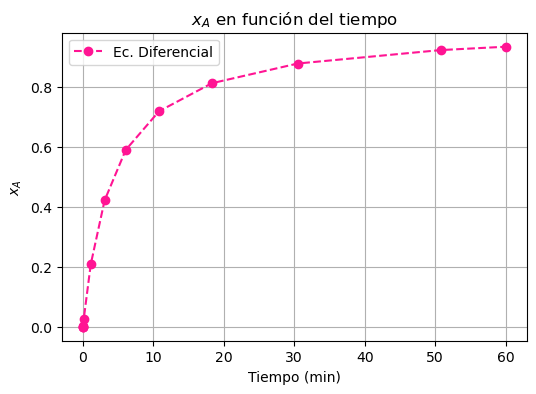

In [42]:
plt.figure(figsize=(6,4))

plt.plot(sol.t,sol.y[0], 'o--', color='deeppink', label='Ec. Diferencial')

plt.title('$x_{A}$ en función del tiempo')
plt.xlabel('Tiempo (min)')
plt.ylabel('$x_{A}$')

plt.grid(True)
plt.legend()
plt.show()

La solución analítica de la ecuación diferencial es 


$$x_A  = 1- \frac{1}{kC_{A0} t+1}$$


Por lo que se puede programar la solución analítica y comparar con el resultado obtenido en el solve_ivp

In [43]:
def analitica(t):
    return 1 - 1 / ((k * CAO * t) + 1)

In [51]:
analitica(10)

0.7030873346070745

Se puede hacer un grafico comparando los resultados de la Ec. Diferencial con la solución analítica para ver la diferencia

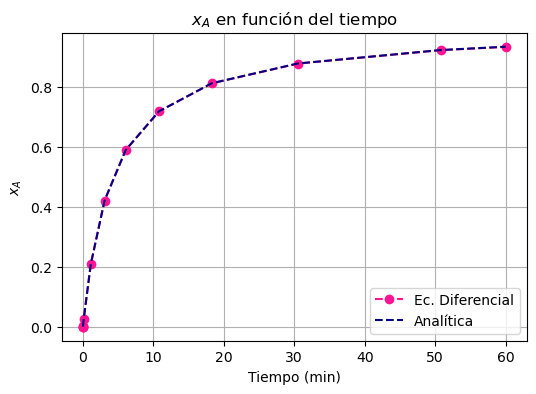

In [52]:
plt.figure(figsize=(6,4))

plt.plot(sol.t,sol.y[0], 'o--', color='deeppink', label='Ec. Diferencial')
plt.plot(sol.t,analitica(sol.t), '--', color='navy', label='Analítica')

plt.title('$x_{A}$ en función del tiempo')
plt.xlabel('Tiempo (min)')
plt.ylabel('$x_{A}$')

plt.grid(True)
plt.legend()
plt.show()